In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import clear_border

In [3]:
def processar_chave(caminho):
    imagem = cv2.imread(caminho)

    if imagem is None:
        raise FileNotFoundError(caminho)

    gray = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2GRAY
    )

    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    binary_inverted = cv2.bitwise_not(binary)

    kernel = np.ones((11, 11), np.uint8)

    closed = cv2.morphologyEx(
        binary_inverted,
        cv2.MORPH_CLOSE,
        kernel
    )

    opened = cv2.morphologyEx(
        closed,
        cv2.MORPH_OPEN,
        kernel
    )

    kernel2 = np.ones((15, 15), np.uint8)
    
    cleaned = cv2.morphologyEx(
        opened,
        cv2.MORPH_CLOSE,
        kernel2
    )

    clear_b = clear_border(cleaned)

    contours, _ = cv2.findContours(
        clear_b,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not contours:
        raise ValueError("Nenhum contorno encontrado")

    contorno = max(contours, key=cv2.contourArea)

    mascara = np.zeros_like(cleaned)

    cv2.drawContours(
        mascara,
        [contorno],
        -1,
        255,
        cv2.FILLED
    )

    return imagem, mascara, contorno

In [4]:
imagem_original, mascara_original, contorno_original = processar_chave(
    "../imagens/Stam.jpeg"
)

In [5]:
rect = cv2.minAreaRect(contorno_original)
center, (w, h), angle = rect

if w < h:
    rotation_angle = angle - 90
else:
    rotation_angle = angle

print(h)
print(w)
print("Ângulo:", rotation_angle)

733.486083984375
385.5722351074219
Ângulo: -105.79020595550537


In [6]:
vertices = cv2.boxPoints(rect)
print(vertices)

[[ 554.9146  1096.5815 ]
 [ 355.32147  390.77386]
 [ 726.34393  285.85358]
 [ 925.9371   991.6612 ]]


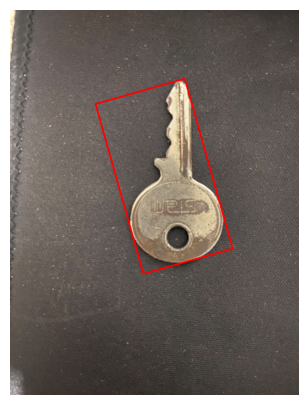

In [7]:
vertices_int = np.int32(vertices)

resultado = imagem_original.copy()

cv2.drawContours(
    resultado,
    [vertices_int],
    0,
    (0, 0, 255),
    5
)

plt.figure(figsize=(12, 5))
plt.imshow(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

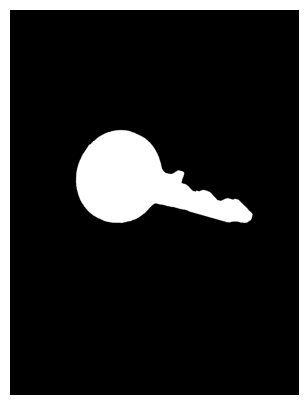

In [8]:
matrix = cv2.getRotationMatrix2D(
    center,
    rotation_angle,
    1.0
)

h_img, w_img = mascara_original.shape

rotacionada = cv2.warpAffine(
    mascara_original,
    matrix,
    (w_img, h_img),
    flags=cv2.INTER_NEAREST
)

plt.figure(figsize=(10, 5))
plt.imshow(rotacionada, cmap="gray")
plt.axis("off")
plt.show()

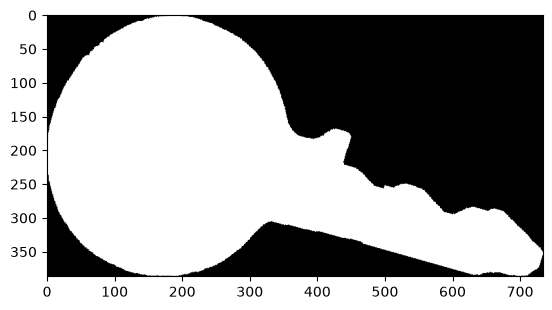

In [9]:
pontos = cv2.findNonZero(rotacionada)

x, y, w, h = cv2.boundingRect(pontos)

recorte = rotacionada[y:y+h, x:x+w]

plt.imshow(recorte, cmap="gray")

In [10]:
largura_alvo = 500
altura_alvo = 200

escala_x = largura_alvo / w
escala_y = altura_alvo / h

escala = min(escala_x, escala_y)

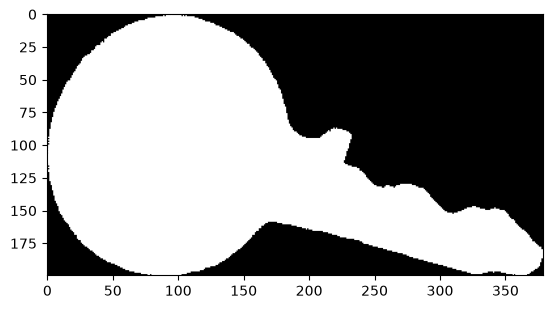

In [11]:
nova_largura = max(1, round(w * escala))
nova_altura = max(1, round(h * escala))

redimensionada = cv2.resize(
    recorte,
    (nova_largura, nova_altura),
    interpolation=cv2.INTER_NEAREST
)

plt.imshow(redimensionada, cmap="gray")

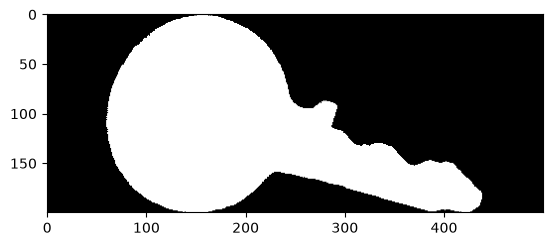

In [12]:
resultado = np.zeros(
    (altura_alvo, largura_alvo),
    dtype=np.uint8
)

inicio_x = (largura_alvo - nova_largura) // 2
inicio_y = (altura_alvo - nova_altura) // 2

resultado[
    inicio_y:inicio_y + nova_altura,
    inicio_x:inicio_x + nova_largura
] = redimensionada

plt.imshow(resultado, cmap="gray")